# Web-App IF: phát hiện chuỗi tấn công trong giá trị tham số HTTP

In [ ]:
%pip install -q numpy==2.5.3 scikit-learn==1.9.1 scipy joblib pandas matplotlib gdown

## 1. Cấu hình

In [2]:
import os, re, math, time, html, collections
from urllib.parse import unquote_plus, urlsplit, parse_qsl
import numpy as np
import pandas as pd
import joblib
import gdown
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import IsolationForest as SkIF
from scipy.stats import spearmanr
from isolationforest import IsolationForest, explain_str

print("numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)
if (np.__version__, sklearn.__version__) != ("2.5.3", "1.9.1"):
    print("Chú ý: khác phiên bản lúc chốt số liệu (numpy 2.5.3, scikit-learn 1.9.1), cây có thể khác đôi chút.")

SEED, N_TREES, MAX_SAMPLES = 7, 300, 1024
TRAIN_FRAC = 0.7
FPR_MAX_VAL = 0.002
Q_GRID = [0.0005, 0.001, 0.0015, 0.002, 0.003, 0.004, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03]
MODEL_OUT = "web_app_if_model.joblib"
DATA_DIR = "data"
DRIVE_URL = ""   # liên kết thư mục dữ liệu trên Google Drive (chia sẻ "Bất kỳ ai có liên kết"); để trống nếu đã chép dữ liệu vào data/
TEP = ["web_get_train.csv", "web_get_test.csv", "web_post_train.csv", "web_post_test.csv"]

PUB = True              # False: bỏ các dòng lấy từ CSIC 2010 và ECML/PKDD 2007
KIEM_TRA_MIEN = True    # kiểm tra miền của Web-Query IF (mục 3)
PUB_SOURCES = {"csic2010"}
NGUON_CONG_KHAI = {"csic2010", "pkdd2007", "post_inject:csic2010", "post_inject:pkdd2007",
                   "ghep:csic2010", "ghep:pkdd2007"}


def data_path(fn):
    return os.path.join(DATA_DIR, fn)


if not all(os.path.exists(data_path(f)) for f in TEP):
    if not DRIVE_URL:
        raise FileNotFoundError("Chưa có dữ liệu: chép các tệp CSV vào thư mục data/ hoặc điền DRIVE_URL.")
    gdown.download_folder(url=DRIVE_URL, output=DATA_DIR, quiet=False, resume=True)


def read(fn):
    d = pd.read_csv(data_path(fn), dtype=str, keep_default_na=False)
    if not PUB:
        d = d[~d["source"].isin(NGUON_CONG_KHAI)].reset_index(drop=True)
    return d

numpy 2.5.3 | scikit-learn 1.9.1 | pandas 3.0.5


## 2. Dữ liệu

In [3]:
def chia(df):
    """Gán 'train' hoặc 'val' cho từng dòng."""
    part = pd.Series("train", index=df.index)
    real = df["source"] == "real_wp"
    t = pd.to_datetime(df.loc[real, "ts"], format="ISO8601")
    part[t.index[t >= t.quantile(TRAIN_FRAC)]] = "val"
    rng = np.random.default_rng(SEED)
    nguon = sorted(set(df["source"]) - {"real_wp"}, key=lambda s: (s in PUB_SOURCES, s))   # nguồn lab trước
    for s in nguon:
        idx = df.index[df["source"] == s]
        so_val = int(round((1 - TRAIN_FRAC) * len(idx)))
        part[idx[rng.permutation(len(idx))[:so_val]]] = "val"
    return part


G, P = read("web_get_train.csv"), read("web_post_train.csv")
G["part"], P["part"] = chia(G), chia(P)
print("GET (giá trị):")
print(G.groupby(["source", "part"]).size().unstack().to_string())
print("\nPOST (giá trị):")
print(P.groupby(["source", "part"]).size().unstack().to_string())
print("\nPOST theo trường:", P["field"].value_counts().to_dict())

GET (giá trị):
part                train    val
source                          
real_wp             87798  37628
synthetic_benign     3018   1294
synthetic_hard        799    343
synthetic_token      2450   1050
synthetic_webparam   1027    440

POST (giá trị):
part             train    val
source                       
real_wp         117247  50249
synthetic_text    1478    634

POST theo trường: {'your-message': 11355, 'content': 10993, '_wpcf7': 10636, '_wpcf7_version': 10636, '_wpcf7_locale': 10636, '_wpcf7_unit_tag': 10636, '_wpcf7_container_post': 10636, 'your-name': 10636, 'your-email': 10636, 'title': 10313, 'status': 10313, 'your-subject': 9787, 'comment': 7660, 'comment_post_ID': 6947, 'comment_parent': 6947, 'author': 6947, 'email': 6947, 'submit': 6947}


## 3. Đơn vị và đặc trưng

In [4]:
FEATS = ["log_len", "r_nonalnum", "r_digit", "r_upper", "entropy", "n_squote", "n_dquote",
         "n_angle", "n_paren", "n_punct_inj", "n_kw", "n_pct", "max_run_sym"]
# Rừng học trên 11 cột; n_angle và n_pct chỉ dùng để diễn giải và kiểm tra miền
FEATS_Q = ["log_len", "r_nonalnum", "r_digit", "r_upper", "entropy", "n_squote", "n_dquote",
           "n_paren", "n_punct_inj", "n_kw", "max_run_sym"]
FEATS_B = list(FEATS_Q)          # Web-Body IF dùng cùng 11 cột
IDX = {"q": [FEATS.index(f) for f in FEATS_Q], "b": [FEATS.index(f) for f in FEATS_B]}
FREE_FIELDS = {"your-message", "content", "comment", "your-subject", "title", "message", "body", "mtxMessage"}

_KW = re.compile(
    r"(?:\b(?:select|union|insert|update|delete|drop|from|where|or|and|exec|"
    r"char|concat|benchmark|sleep|script|alert|onerror|onload|iframe|eval|"
    r"javascript|cmd|etc|passwd|boot\.ini)\b)|(?:--)|(?:/\*)|(?:\.\.[\\/])|(?:<\s*/?\s*\w)",
    re.IGNORECASE)
_PCT = re.compile(r"%[0-9a-fA-F]{2}")
_INJ = set(";|&`$\\{}")
_TAG = re.compile(r"</?[a-zA-Z][^<>]{0,300}>|\bon[a-zA-Z]{2,}\s*=\s*\S+", re.IGNORECASE)
_URL_RE = re.compile(r"^https?://", re.IGNORECASE)
_HOST_RE = re.compile(r"^[A-Za-z0-9.-]+(?::\d{1,5})?$")
_PATH_RE = re.compile(r"^/[A-Za-z0-9/_\-.]*$")


def _entropy(s):
    if not s:
        return 0.0
    n = len(s)
    return float(-sum((c / n) * math.log2(c / n) for c in collections.Counter(s).values()))


def _max_run_symbol(s):
    best = cur = 0
    for ch in s:
        if ch.isalnum():
            cur = 0
        else:
            cur += 1
            best = max(best, cur)
    return best


def feature_vector(s):
    n = len(s)
    if n == 0:
        return [0.0] * len(FEATS)
    nonalnum = sum(1 for ch in s if not ch.isalnum())
    digit = sum(1 for ch in s if ch.isdigit())
    upper = sum(1 for ch in s if ch.isupper())
    return [math.log1p(n), nonalnum / n, digit / n, upper / n, _entropy(s),
            float(s.count("'")), float(s.count('"')), float(s.count("<") + s.count(">")),
            float(s.count("(") + s.count(")")), float(sum(s.count(c) for c in _INJ)),
            float(len(_KW.findall(s))), float(len(_PCT.findall(s))), float(_max_run_symbol(s))]


def decode_once(s):
    try:
        return unquote_plus(s).replace("\x00", "%00")
    except Exception:
        return s


def is_plain_path(v):
    return bool(_PATH_RE.match(v)) and ".." not in v


def la_url_hop_le(v):
    """URL http(s) có tên máy hợp lệ, đường dẫn trơn hoặc rỗng, không có phần '#'."""
    if not _URL_RE.match(v) or "#" in v:
        return False
    try:
        u = urlsplit(v)
    except ValueError:
        return False
    return bool(_HOST_RE.match(u.netloc)) and (u.path == "" or is_plain_path(u.path))


def expand_value(v, known_paths=()):
    """Các đơn vị của một giá trị tham số."""
    if la_url_hop_le(v):
        return [decode_once(x) for _, x in parse_qsl(urlsplit(v).query, keep_blank_values=True) if x]
    if v in known_paths and is_plain_path(v):
        return []
    return [v]


def the(s):
    """Các đoạn trông như thẻ HTML hoặc thuộc tính sự kiện trong văn bản tự do."""
    return _TAG.findall(s)


# Thẻ định dạng WordPress cho phép trong bình luận: $allowedtags và wp_allowed_protocols()
ALLOWED_TAGS = {"a": ["href", "title"], "abbr": ["title"], "acronym": ["title"], "b": [], "blockquote": ["cite"],
                "cite": [], "code": [], "del": ["datetime"], "em": [], "i": [], "q": ["cite"], "s": [], "strike": [],
                "strong": []}
ALLOWED_PROTOCOLS = ["http", "https", "ftp", "ftps", "mailto", "news", "irc", "irc6", "ircs", "gopher", "nntp", "feed",
                     "telnet", "mms", "rtsp", "sms", "svn", "tel", "fax", "xmpp", "webcal", "urn"]
_URI_ATTRS = {"href", "cite"}
_TAG_FULL = re.compile(r"<(/?)([a-zA-Z][a-zA-Z0-9]*)([^<>]*)>")
_ATTR = re.compile(r'\s*([a-zA-Z][-a-zA-Z0-9_:.]*)(?:\s*=\s*(?:"([^"]*)"|\'([^\']*)\'|([^\s"\'=<>`]+)))?')
_OPEN = re.compile(r"<[a-zA-Z/!?]")


def _uri_ok(v):
    v = re.sub(r"[\x00-\x20\x7f]", "", html.unescape(v)).lower()
    head = re.split(r"[/?#]", v, maxsplit=1)[0]
    return ":" not in head or head.split(":", 1)[0] in ALLOWED_PROTOCOLS


def the_duoc_phep(m):
    """Thẻ có tên, mọi thuộc tính và giao thức liên kết đều nằm trong chính sách."""
    close, name, rest = m.group(1), m.group(2).lower(), m.group(3)
    if name not in ALLOWED_TAGS:
        return False
    if close:
        return rest.strip() == ""
    rest = rest.rstrip()
    if rest.endswith("/"):
        rest = rest[:-1]
    pos = 0
    while pos < len(rest):
        a = _ATTR.match(rest, pos)
        if not a or a.end() == pos:
            return False
        key = a.group(1).lower()
        val = next((g for g in a.group(2, 3, 4) if g is not None), None)
        if key not in ALLOWED_TAGS[name]:
            return False
        if key in _URI_ATTRS and (val is None or not _uri_ok(val)):
            return False
        pos = a.end()
    return True


def trong_the_chua_dong(s, i):
    """Vị trí i nằm sau một dấu < mở thẻ chưa đóng, nên trình duyệt coi là một phần của thẻ trước."""
    return _OPEN.search(s, s.rfind(">", 0, i) + 1, i) is not None


def bo_the_duoc_phep(s):
    """Bỏ phần đánh dấu của thẻ được phép, giữ chữ bên trong; thẻ khác giữ nguyên để được chấm."""
    def thay(m):
        return "" if the_duoc_phep(m) and not trong_the_chua_dong(s, m.start()) else m.group(0)
    return _TAG_FULL.sub(thay, s)


def is_free(field, v):
    """Trường văn bản tự do, chỉ xét theo tên trường."""
    return field in FREE_FIELDS


KNOWN_PATHS = sorted({v for v in G.loc[G["part"] == "train", "value"] if is_plain_path(v)})
print("Đường dẫn trơn đã thấy khi huấn luyện:", len(KNOWN_PATHS))

ENUM_MAX, ENUM_MIN = 10, 100
ngan = P[(P["part"] == "train") & ~P["field"].isin(FREE_FIELDS)]
thong_ke = ngan.groupby("field")["value"].agg(["nunique", "size"])
it_gia_tri = thong_ke.index[(thong_ke["nunique"] <= ENUM_MAX) & (thong_ke["size"] >= ENUM_MIN)]
KNOWN_VALUES = {f: set(ngan.loc[ngan["field"] == f, "value"]) for f in it_gia_tri}
print("Trường ngắn POST có giá trị đã biết:", {f: sorted(v) for f, v in sorted(KNOWN_VALUES.items())})

_cache = {}


def fv(u):
    if u not in _cache:
        _cache[u] = feature_vector(u)
    return _cache[u]


def don_vi(field, value, method="GET"):
    """(mô hình phụ trách, [(mô hình, đơn vị), ...]); 'q' là Web-Query IF, 'b' là Web-Body IF."""
    if method == "POST" and is_free(field, value):
        v = bo_the_duoc_phep(value)
        return "b", [("b", v)] + [("q", t) for t in the(v)]
    if method == "POST" and value in KNOWN_VALUES.get(field, ()):
        return "q", []
    return "q", [("q", u) for u in expand_value(value, KNOWN_PATHS)]


def ma_tran(units):
    return np.array([fv(u) for u in units], float).reshape(len(units), len(FEATS))


train_G = G[G["part"] == "train"]
train_P = P[P["part"] == "train"]
Utr_q = [u for v in train_G["value"] for u in expand_value(v, KNOWN_PATHS)]
Utr_b = [v for f, v in zip(train_P["field"], train_P["value"]) if is_free(f, v)]
Xq, Xb = ma_tran(Utr_q), ma_tran(Utr_b)

HANG_Q = [j for j in range(len(FEATS)) if np.ptp(Xq[:, j]) == 0] if KIEM_TRA_MIEN else []
GT_HANG_Q = Xq[0, HANG_Q] if HANG_Q else np.empty(0)


def ngoai_mien(X):
    """Đơn vị có đặc trưng hằng (ở tập huấn luyện Web-Query) khác giá trị hằng đó."""
    X = np.asarray(X, float).reshape(-1, len(FEATS))
    if not HANG_Q:
        return np.zeros(len(X), bool)
    return (np.abs(X[:, HANG_Q] - GT_HANG_Q) > 1e-12).any(1)


def kiem_mien(field, value, method):
    """Chỉ kiểm tra miền cho giá trị tham số, không cho văn bản tự do."""
    return bool(HANG_Q) and not (method == "POST" and is_free(field, value))


print(f"Đơn vị huấn luyện: Web-Query {len(Xq):,} | Web-Body {len(Xb):,}")
print("Kiểm tra miền của Web-Query IF:", {FEATS[j]: float(v) for j, v in zip(HANG_Q, GT_HANG_Q)} or "tắt")
print("\nTỉ lệ đơn vị huấn luyện có giá trị khác 0 theo đặc trưng (%):")
print(pd.DataFrame({"Web-Query": (Xq != 0).mean(0) * 100, "Web-Body": (Xb != 0).mean(0) * 100,
                    "Web-Query IF dùng": [f in FEATS_Q for f in FEATS], "Web-Body IF dùng": [f in FEATS_B for f in FEATS]},
                   index=FEATS).round(2).to_string())

Đường dẫn trơn đã thấy khi huấn luyện: 14


Trường ngắn POST có giá trị đã biết: {'_wpcf7': ['1925'], '_wpcf7_container_post': ['1926'], '_wpcf7_locale': ['en_US'], '_wpcf7_unit_tag': ['wpcf7-f1925-p1926-o1'], '_wpcf7_version': ['6.2.2'], 'comment_parent': ['0'], 'comment_post_ID': ['1787', '1788', '1885', '1926', '1929'], 'status': ['draft'], 'submit': ['Post Comment']}


Đơn vị huấn luyện: Web-Query 63,786 | Web-Body 35,055
Kiểm tra miền của Web-Query IF: {'n_angle': 0.0, 'n_pct': 0.0}

Tỉ lệ đơn vị huấn luyện có giá trị khác 0 theo đặc trưng (%):
             Web-Query  Web-Body  Web-Query IF dùng  Web-Body IF dùng
log_len         100.00    100.00               True              True
r_nonalnum       20.95    100.00               True              True
r_digit          67.26     62.96               True              True
r_upper           7.30     99.90               True              True
entropy          82.00    100.00               True              True
n_squote          0.22      5.63               True              True
n_dquote          0.21      0.91               True              True
n_angle           0.00      0.00              False             False
n_paren           0.12      1.75               True              True
n_punct_inj       0.24      1.68               True              True
n_kw              0.21      6.62               Tru

## 4. Huấn luyện

In [5]:
def fit_model(X, idx):
    """Học một mô hình trên X (đủ 13 cột); rừng chỉ nhận các cột idx đã chuẩn hóa."""
    mu = X.mean(0)
    sd = X.std(0)
    sd = np.where(sd < 1e-9, 1.0, sd)
    Z = ((X - mu) / sd)[:, idx]
    own = IsolationForest(n_estimators=N_TREES, max_samples=MAX_SAMPLES, random_state=SEED).fit(Z)
    sk = SkIF(n_estimators=N_TREES, max_samples=min(MAX_SAMPLES, len(Z)), random_state=SEED).fit(Z)
    med = np.median(X, 0)
    mad = np.median(np.abs(X - med), 0)
    scale = np.where(mad > 1e-9, 1.4826 * mad, sd)
    return {"own": own, "sk": sk, "mu": mu, "sd": sd, "idx": list(idx), "med": med, "scale": scale,
            "s_tr": own.anomaly_score(Z), "s_sk": -sk.score_samples(Z)}


def diem(m, X, which="own"):
    if len(X) == 0:
        return np.empty(0)
    Z = ((np.asarray(X, float) - m["mu"]) / m["sd"])[:, m["idx"]]
    if which == "own":
        return m["own"].anomaly_score(Z)
    return -m["sk"].score_samples(Z)


t0 = time.time()
MOD = {"q": fit_model(Xq, IDX["q"]), "b": fit_model(Xb, IDX["b"])}
print(f"Huấn luyện xong trong {time.time() - t0:.1f}s")

Huấn luyện xong trong 14.1s


## 5. Chọn ngưỡng trên tập kiểm định

In [6]:
def diem_gia_tri(df, which="own", method="GET"):
    """Điểm cao nhất của mỗi giá trị theo từng mô hình (-1 nếu không có đơn vị) và mô hình phụ trách.
    S["q_rung"] là điểm Web-Query khi chỉ dùng rừng, không kiểm tra miền."""
    S = {"q": np.full(len(df), -1.0), "b": np.full(len(df), -1.0), "q_rung": np.full(len(df), -1.0)}
    mo_hinh = np.empty(len(df), object)
    gom = {"q": ([], [], []), "b": ([], [], [])}          # chỉ số giá trị, đơn vị, có kiểm tra miền
    for i, (f, v) in enumerate(zip(df["field"], df["value"])):
        mo_hinh[i], cac_don_vi = don_vi(f, v, method)
        km = kiem_mien(f, v, method)
        for m, u in cac_don_vi:
            gom[m][0].append(i)
            gom[m][1].append(u)
            gom[m][2].append(km and m == "q")
    for m, (ii, us, kk) in gom.items():
        if not ii:
            continue
        X = ma_tran(us)
        s = diem(MOD[m], X, which)
        ii, kk = np.array(ii), np.array(kk, bool)
        if m == "q":
            np.maximum.at(S["q_rung"], ii, s)
        if kk.any():
            s = np.where(kk & ngoai_mien(X), 1.0, s)
        np.maximum.at(S[m], ii, s)
    return S, mo_hinh


def vuot_nguong(S, which="own"):
    """Giá trị bị gắn cờ khi có đơn vị vượt ngưỡng của chính mô hình chấm nó."""
    k = "thr" if which == "own" else "thr_sk"
    return (S["q"] > SEL["q"][k]) | (S["b"] > SEL["b"][k])


def mien(df):
    return np.where(df["source"].isin(PUB_SOURCES), "CSIC", "lab")


Gv, Pv = G[G["part"] == "val"], P[P["part"] == "val"]
SG, _ = diem_gia_tri(Gv)
SP, mP = diem_gia_tri(Pv, method="POST")
dG, dP = mien(Gv), mien(Pv)

SEL = {}
cau_hinh = [("q", "Web-Query IF", SG["q"], dG, SP["q"][mP == "q"]),
            ("b", "Web-Body IF", SP["b"][mP == "b"], dP[mP == "b"], None)]
for m, ten, s_val, d_val, truong_ngan in cau_hinh:
    cac_mien = sorted(set(d_val))
    rows = []
    for q in Q_GRID:
        thr = float(np.quantile(MOD[m]["s_tr"], 1 - q))
        r = {"SCORE_Q": q, "Ngưỡng": round(thr, 4), "FPR kiểm định (%)": round(100 * (s_val > thr).mean(), 3)}
        if len(cac_mien) > 1:
            for dm in cac_mien:
                r[f"FPR {dm} (%)"] = round(100 * (s_val[d_val == dm] > thr).mean(), 3)
        if truong_ngan is not None:
            r["FPR trường ngắn POST (%)"] = round(100 * (truong_ngan > thr).mean(), 3)
        rows.append(r)
    T = pd.DataFrame(rows)
    cot = [f"FPR {dm} (%)" for dm in cac_mien] if len(cac_mien) > 1 else ["FPR kiểm định (%)"]
    dat = T[(T[cot] <= 100 * FPR_MAX_VAL).all(axis=1)]
    assert len(dat), f"{ten}: không có SCORE_Q nào đạt FPR kiểm định ≤ {100 * FPR_MAX_VAL}%"
    q = float(dat["SCORE_Q"].max())
    SEL[m] = {"q": q, "thr": float(np.quantile(MOD[m]["s_tr"], 1 - q)),
              "thr_sk": float(np.quantile(MOD[m]["s_sk"], 1 - q))}
    print(f"\n{ten}: {len(s_val):,} giá trị kiểm định")
    print(T.to_string(index=False))
    print(f">> SCORE_Q = {q} | ngưỡng tự cài {SEL[m]['thr']:.4f} | ngưỡng scikit-learn {SEL[m]['thr_sk']:.4f}")


Web-Query IF: 40,755 giá trị kiểm định
 SCORE_Q  Ngưỡng  FPR kiểm định (%)  FPR trường ngắn POST (%)
  0.0005  0.7991              0.010                     0.000
  0.0010  0.7984              0.032                     0.000
  0.0015  0.7015              0.106                     0.000
  0.0020  0.6882              0.128                     0.000
  0.0030  0.6714              0.184                     0.000
  0.0040  0.6634              0.238                     0.000
  0.0050  0.6462              0.294                     0.000
  0.0075  0.6160              0.471                     0.000
  0.0100  0.6063              0.662                     0.000
  0.0150  0.5932              0.954                     0.056
  0.0200  0.5797              1.207                     0.056
  0.0300  0.5682              1.772                     0.148
>> SCORE_Q = 0.003 | ngưỡng tự cài 0.6714 | ngưỡng scikit-learn 0.6692

Web-Body IF: 15,053 giá trị kiểm định
 SCORE_Q  Ngưỡng  FPR kiểm định (%)
  0.0005

## 6. Kiểm thử

In [7]:
def do_vuot(S, which="own"):
    """Điểm trừ ngưỡng của mô hình chấm, lấy lớn nhất trên hai mô hình; lớn hơn 0 nghĩa là bị gắn cờ."""
    k = "thr" if which == "own" else "thr_sk"
    q = np.where(S["q"] >= 0, S["q"] - SEL["q"][k], -np.inf)
    b = np.where(S["b"] >= 0, S["b"] - SEL["b"][k], -np.inf)
    return np.maximum(q, b)


def nguon_yeu_cau(x):
    """Nguồn của một yêu cầu: lab_attack được ưu tiên hơn lab_manual."""
    if (x == "lab_attack").any():
        return "lab_attack"
    return next((v for v in x if v.startswith("lab")), x.iloc[0])


def cham_yeu_cau(df, method, which="own"):
    """Chấm từng giá trị rồi gộp theo yêu cầu (req_id)."""
    S, md = diem_gia_tri(df, which, method)
    k = "thr" if which == "own" else "thr_sk"
    d = df.assign(s=np.maximum(S["q"], S["b"]), m=do_vuot(S, which), mo_hinh=md, vuot=vuot_nguong(S, which),
                  vuot_rung=(S["q_rung"] > SEL["q"][k]) | (S["b"] > SEL["b"][k]))
    return d.groupby("req_id").agg(label=("label", "first"), source=("source", nguon_yeu_cau),
                                   attack_type=("attack_type", lambda x: next((v for v in x if v), "")),
                                   vuot=("vuot", "any"), vuot_rung=("vuot_rung", "any"),
                                   s=("s", "max"), m=("m", "max"))


PUB_ATK = {"csic2010", "pkdd2007", "post_inject:csic2010", "post_inject:pkdd2007"}

GT, PT = read("web_get_test.csv"), read("web_post_test.csv")
RG, RP = cham_yeu_cau(GT, "GET"), cham_yeu_cau(PT, "POST")

for ten, R in (("GET", RG), ("POST", RP)):
    n = R[R["label"] == "normal"]
    a = R[R["label"] == "attack"]
    print(f"\n== {ten}: {len(n):,} yêu cầu hợp lệ, {len(a):,} yêu cầu tấn công (tập chính)")

    nl = n[~n["source"].isin(PUB_SOURCES)]
    print("Tỉ lệ báo nhầm theo nguồn (%):", (n.groupby("source")["vuot"].mean() * 100).round(3).to_dict(),
          f"| chung {100 * n['vuot'].mean():.3f}%"
          + (f" | riêng phần lab {100 * nl['vuot'].mean():.3f}%" if len(nl) < len(n) else ""))

    tab = a.pivot_table(index="source", columns="attack_type", values="vuot", aggfunc="mean") * 100
    tab["chung"] = a.groupby("source")["vuot"].mean() * 100
    print("Độ phủ theo nguồn và loại tấn công, tập chính (%):")
    print(tab.round(2).to_string())

    pa = a["source"].isin(PUB_ATK)
    gh = a["source"].str.startswith("ghep:")
    print(f"Độ phủ chung (tập chính): {100 * a['vuot'].mean():.2f}% | chuỗi gốc {100 * a.loc[~gh, 'vuot'].mean():.2f}% "
          f"trên {int((~gh).sum()):,} yêu cầu | chuỗi ghép {100 * a.loc[gh, 'vuot'].mean():.2f}% trên {int(gh.sum()):,} yêu cầu")
    if pa.any():
        print(f"Chuỗi gốc: phần lab {100 * a.loc[~gh & ~pa, 'vuot'].mean():.2f}% | "
              f"phần công khai {100 * a.loc[pa, 'vuot'].mean():.2f}%")
    print("Độ phủ theo loại tấn công, tập chính (%):", (a.groupby("attack_type")["vuot"].mean() * 100).round(2).to_dict())
    print("Số yêu cầu bị bỏ sót theo loại tấn công, tập chính:",
          (~a["vuot"]).groupby(a["attack_type"]).sum().astype(int).to_dict())
    print("Theo loại tấn công, chuỗi gốc / chuỗi ghép (%):")
    print(pd.DataFrame({"gốc (yêu cầu)": a[~gh].groupby("attack_type").size(),
                        "gốc (%)": a[~gh].groupby("attack_type")["vuot"].mean() * 100,
                        "ghép (yêu cầu)": a[gh].groupby("attack_type").size(),
                        "ghép (%)": a[gh].groupby("attack_type")["vuot"].mean() * 100}).round(2).to_string())
    if HANG_Q:
        them = R["vuot"] & ~R["vuot_rung"]            # chỉ bị gắn cờ nhờ kiểm tra miền
        print(f"Kiểm tra miền: thêm {int(them[n.index].sum())} yêu cầu hợp lệ và {int(them[a.index].sum())} yêu cầu tấn công "
              f"của tập chính bị gắn cờ so với chỉ dùng rừng | chỉ dùng rừng: FPR {100 * R.loc[n.index, 'vuot_rung'].mean():.3f}%, "
              f"độ phủ tập chính {100 * R.loc[a.index, 'vuot_rung'].mean():.2f}%")

inj = PT[(PT["injected"] == "1") & PT["source"].str.startswith(("post_inject", "ghep:"))].copy()
inj["loai_truong"] = np.where([is_free(f, v) for f, v in zip(inj["field"], inj["value"])], "văn bản tự do", "trường ngắn")
inj["phan"] = np.where(inj["source"].str.startswith("ghep:"), "chuỗi ghép",
                       np.where(inj["source"].isin(PUB_ATK), "công khai", "lab"))
inj = inj.merge(RP[["vuot"]], left_on="req_id", right_index=True)
print("\nPOST chèn chuỗi, tập chính: độ phủ theo phần dữ liệu, loại trường và cách chèn (%)")
print((inj.pivot_table(index=["phan", "loai_truong", "inject_mode"], columns="attack_type", values="vuot",
                       aggfunc="mean") * 100).round(2).to_string())
print("\nPOST chèn chuỗi, tập chính: độ phủ theo phần dữ liệu và loại trường")
print(inj.groupby(["phan", "loai_truong"])["vuot"].agg(**{"yêu cầu": "size", "bỏ sót": lambda x: int((~x).sum()),
                                                          "độ phủ (%)": lambda x: round(100 * x.mean(), 2)}).to_string())


== GET: 27,010 yêu cầu hợp lệ, 12,207 yêu cầu tấn công (tập chính)
Tỉ lệ báo nhầm theo nguồn (%): {'csic2010': 0.583, 'lab_manual': 0.0, 'real_wp': 0.0, 'synthetic_benign': 2.488, 'synthetic_hard': 10.204, 'synthetic_token': 1.333, 'synthetic_webparam': 0.0} | chung 0.533% | riêng phần lab 0.522%
Độ phủ theo nguồn và loại tấn công, tập chính (%):
attack_type       cmdi  path-traversal    sqli    xss   chung
source                                                       
csic2010           NaN             NaN  100.00  100.0  100.00
ghep:csic2010      NaN             NaN   99.61  100.0   99.77
ghep:lab_attack    NaN           85.71  100.00  100.0   97.56
ghep:pkdd2007    93.30           79.96   98.60  100.0   95.92
lab_attack         NaN           87.50  100.00  100.0   99.78
pkdd2007         93.87           79.84   99.50  100.0   96.35
Độ phủ chung (tập chính): 97.03% | chuỗi gốc 97.58% trên 7,094 yêu cầu | chuỗi ghép 96.26% trên 5,113 yêu cầu
Chuỗi gốc: phần lab 99.78% | phần công khai 

attack_type                            cmdi  path-traversal   sqli     xss
phan       loai_truong   inject_mode                                      
chuỗi ghép trường ngắn   append       95.52           80.07  98.37  100.00
           văn bản tự do append       56.96           38.33  89.25   88.91
công khai  trường ngắn   replace      95.59           79.89  99.53  100.00
           văn bản tự do embed          NaN             NaN    NaN   91.28
                         replace      77.66           55.66  96.26   91.35

POST chèn chuỗi, tập chính: độ phủ theo phần dữ liệu và loại trường
                          yêu cầu  bỏ sót  độ phủ (%)
phan       loai_truong                               
chuỗi ghép trường ngắn       1839      85       95.38
           văn bản tự do     1836     472       74.29
công khai  trường ngắn       1369      55       95.98
           văn bản tự do     2524     373       85.22


In [8]:
print("Thử nghiệm thủ công trên lab: từng giá trị khác nhau và kết quả")
BO_QUA = {"Submit", "btnSign", "submit", "comment_post_ID", "comment_parent", "ver", "page_id", "rest_route",
          "paged", "p", "cat"}
ket_qua = {}
for pt, df in (("GET", GT), ("POST", PT)):
    d = df[df["source"].str.startswith("lab")]
    S, _ = diem_gia_tri(d, "own", pt)
    for f, v, sq, sb, vu in zip(d["field"], d["value"], S["q"], S["b"], vuot_nguong(S)):
        m = "q" if sq - SEL["q"]["thr"] >= sb - SEL["b"]["thr"] else "b"      # mô hình có độ vượt ngưỡng lớn hơn
        ket_qua[(pt, f, v)] = (round(float(sq if m == "q" else sb), 3), m, bool(vu))

lab = pd.concat([GT.assign(pt="GET"), PT.assign(pt="POST")])
lab = lab[lab["source"].str.startswith("lab") & ~lab["field"].isin(BO_QUA)]
rows = [(pt, f, v[:70], at or "hợp lệ", *ket_qua[(pt, f, v)])
        for pt, f, v, at in lab[["pt", "field", "value", "attack_type"]].drop_duplicates().itertuples(index=False)]
T = pd.DataFrame(rows, columns=["phương thức", "trường", "giá trị", "nhãn", "điểm", "mô hình", "vượt ngưỡng"])
print(T.sort_values(["phương thức", "nhãn", "trường"]).to_string(index=False))

Thử nghiệm thủ công trên lab: từng giá trị khác nhau và kết quả


phương thức     trường                                                                giá trị           nhãn  điểm mô hình  vượt ngưỡng
        GET          s                                                               suricata         hợp lệ 0.412       q        False
        GET       page                                                 ../../../../etc/passwd path-traversal 0.724       q         True
        GET       page                                           ../../../../../../etc/passwd path-traversal 0.724       q         True
        GET       page                                           ....//....//....//etc/passwd path-traversal 0.724       q         True
        GET       page                                                    ../../../etc/passwd path-traversal 0.720       q         True
        GET       page                                                         /etc/passwd%00 path-traversal 1.000       q         True
        GET       page                          

SQL Injection và XSS, GET: recall 99.62% trên 9,322 yêu cầu tấn công
SQL Injection và XSS, POST: recall 96.00% trên 5,874 yêu cầu tấn công


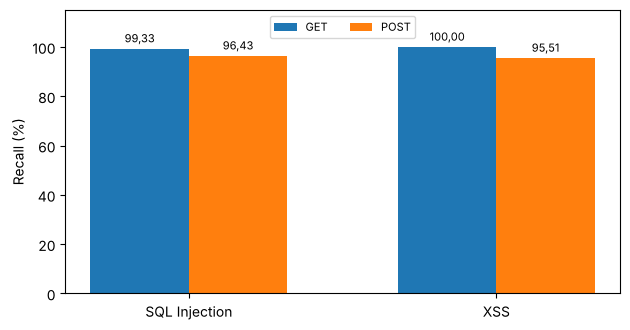

Command injection và path traversal, GET: recall 88.63% trên 2,885 yêu cầu tấn công
Command injection và path traversal, POST: recall 73.83% trên 2,874 yêu cầu tấn công


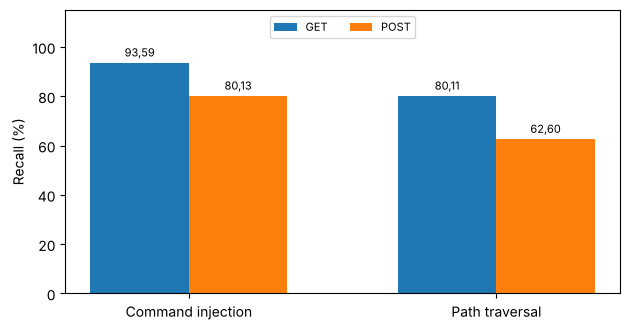

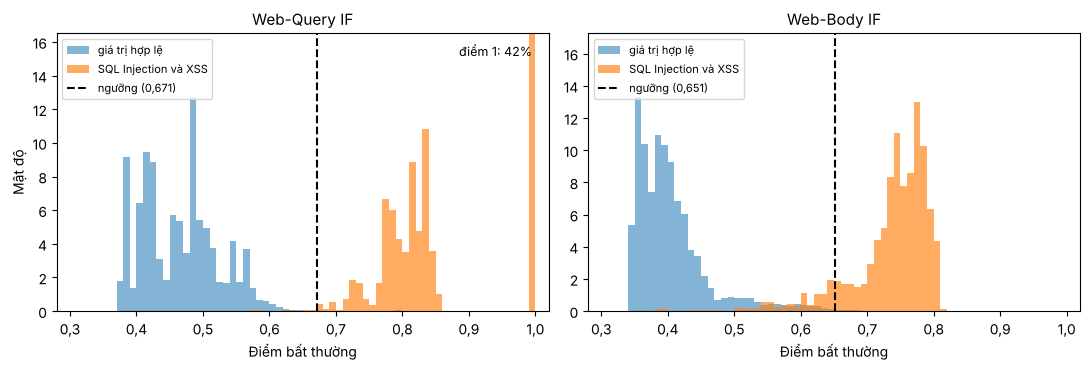

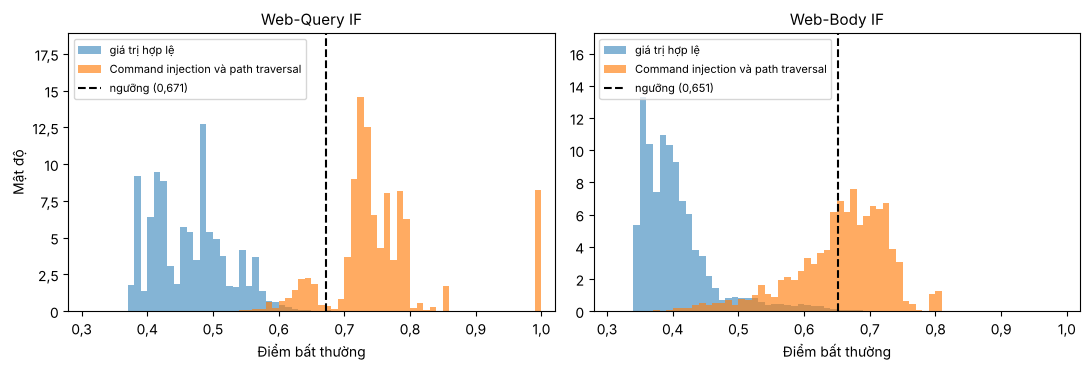

Web-Query IF: 120,242 giá trị hợp lệ, trung vị điểm 0.463, 98.9% dưới 0,6, 0.143% vượt ngưỡng
Web-Body IF: 23,999 giá trị hợp lệ, trung vị điểm 0.393, 98.4% dưới 0,6, 0.317% vượt ngưỡng
     mô hình              loại  số giá trị  trung vị điểm  % vượt ngưỡng  % điểm 1
Web-Query IF     SQL Injection        6859          0.812         99.315    10.264
Web-Query IF               XSS        6583          1.000         99.909    75.042
Web-Query IF Command injection        2626          0.761         94.136     9.216
Web-Query IF    Path traversal        1526          0.728         80.079     6.619
 Web-Body IF     SQL Injection        1480          0.741         93.243     0.000
 Web-Body IF               XSS        1336          0.770         87.949     0.000
 Web-Body IF Command injection        1040          0.682         68.365     0.000
 Web-Body IF    Path traversal         567          0.649         48.325     0.000


In [9]:
from matplotlib.ticker import FuncFormatter


def so(v, n=2):
    """Số thập phân dùng dấu phẩy như trong báo cáo."""
    return f"{v:.{n}f}".replace(".", ",")


truc_y = FuncFormatter(lambda v, p: f"{v:g}".replace(".", ","))
os.makedirs("docs", exist_ok=True)

# Bốn loại tấn công được vẽ theo hai nhóm: SQL Injection với XSS, command injection với path traversal.
# Mỗi nhóm có một hình recall (theo yêu cầu của tập chính) và một hình phân bố điểm (theo giá trị tham số).
# Hình đồng thời được ghi vào docs/ để README dùng.
NHOM = (("sqli_xss", "SQL Injection và XSS", (("sqli", "SQL Injection"), ("xss", "XSS"))),
        ("cmdi_pt", "Command injection và path traversal",
         (("cmdi", "Command injection"), ("path-traversal", "Path traversal"))))

# Recall theo loại tấn công, GET và POST
for key, ten_nhom, loai in NHOM:
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    x = np.arange(len(loai))
    w = 0.32
    for j, (ten, R, mau) in enumerate((("GET", RG, "tab:blue"), ("POST", RP, "tab:orange"))):
        a = R[R["label"] == "attack"]
        v = [100 * a.loc[a["attack_type"] == k, "vuot"].mean() for k, _ in loai]
        trong_nhom = a["attack_type"].isin([k for k, _ in loai])
        print(f"{ten_nhom}, {ten}: recall {100 * a.loc[trong_nhom, 'vuot'].mean():.2f}% "
              f"trên {int(trong_nhom.sum()):,} yêu cầu tấn công")
        cot = ax.bar(x + (j - 0.5) * w, v, w, color=mau, label=ten)
        for c, vv in zip(cot, v):
            ax.text(c.get_x() + c.get_width() / 2, vv + 1.5, so(vv), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([t for _, t in loai])
    ax.set_ylim(0, 115)
    ax.set_yticks(range(0, 101, 20))
    ax.set_ylabel("Recall (%)")
    ax.legend(loc="upper center", ncol=2, fontsize=8)
    plt.tight_layout()
    fig.savefig(f"docs/web_app_if_recall_{key}.png", dpi=220)
    plt.show()

# Phân bố điểm. Mỗi giá trị tham số do đúng một mô hình chấm: query GET và trường ngắn POST do Web-Query IF,
# văn bản tự do POST do Web-Body IF. Hình trái là Web-Query IF, hình phải là Web-Body IF; mỗi hình so phân bố
# điểm của giá trị hợp lệ với giá trị mang tấn công của nhóm, kèm ngưỡng của mô hình.
V = []
for ten, df in (("GET", GT), ("POST", PT)):
    S, _ = diem_gia_tri(df, "own", ten)
    V.append(df.assign(q=S["q"], b=S["b"]))
V = pd.concat(V, ignore_index=True)
hop_le = V["label"] == "normal"
mang = V["injected"] == "1"
MO_HINH = (("q", "Web-Query IF"), ("b", "Web-Body IF"))
bins = np.linspace(0.30, 1.0, 71)
for key, ten_nhom, loai in NHOM:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for a_, (m, ten_mh) in zip(ax, MO_HINH):
        co = V[m] >= 0
        thr = SEL[m]["thr"]
        x0 = V.loc[hop_le & co, m]
        x1 = V.loc[mang & co & V["attack_type"].isin([k for k, _ in loai]), m]
        h0 = a_.hist(x0, bins=bins, alpha=0.55, density=True, color="tab:blue", label="giá trị hợp lệ")
        h1 = a_.hist(x1, bins=bins, alpha=0.65, density=True, color="tab:orange", label=ten_nhom)
        # cột điểm 1 (bước kiểm tra miền) có thể rất cao: cắt trục theo các cột còn lại và ghi tỉ lệ lên cột
        cao = max(h0[0].max(), h1[0][:-1].max())
        if h1[0][-1] > 1.3 * cao:
            p1 = 100 * float((x1 >= 0.995).mean())
            a_.annotate(f"điểm 1: {so(p1, 0)}%", xy=(0.995, 1.25 * cao), ha="right", va="top", fontsize=9)
        a_.axvline(thr, color="k", ls="--", label=f"ngưỡng ({so(thr, 3)})")
        a_.set_ylim(0, 1.3 * cao)
        a_.set_xlim(0.28, 1.02)
        a_.set_title(ten_mh, fontsize=11)
        a_.set_xlabel("Điểm bất thường")
        a_.xaxis.set_major_formatter(FuncFormatter(lambda v, p: so(v, 1)))
        a_.yaxis.set_major_formatter(truc_y)
        a_.legend(loc="upper left", fontsize=8)
    ax[0].set_ylabel("Mật độ")
    plt.tight_layout()
    fig.savefig(f"docs/web_app_if_phan_bo_{key}.png", dpi=200)
    plt.show()

# Số liệu dùng khi mô tả hai hình phân bố điểm
bang = []
for m, ten_mh in MO_HINH:
    co = V[m] >= 0
    thr = SEL[m]["thr"]
    x0 = V.loc[hop_le & co, m]
    print(f"{ten_mh}: {len(x0):,} giá trị hợp lệ, trung vị điểm {np.median(x0):.3f}, "
          f"{100 * (x0 < 0.6).mean():.1f}% dưới 0,6, {100 * (x0 > thr).mean():.3f}% vượt ngưỡng")
    for _, _, loai in NHOM:
        for k, ten_loai in loai:
            x1 = V.loc[mang & co & (V["attack_type"] == k), m]
            bang.append((ten_mh, ten_loai, len(x1), float(np.median(x1)), 100 * float((x1 > thr).mean()),
                         100 * float((x1 >= 0.995).mean())))
print(pd.DataFrame(bang, columns=["mô hình", "loại", "số giá trị", "trung vị điểm", "% vượt ngưỡng", "% điểm 1"])
      .round(3).to_string(index=False))

## 7. So sánh bản tự cài và scikit-learn

In [10]:
Uq = [u for v in Gv["value"] for u in expand_value(v, KNOWN_PATHS)]
Ub = [v for f, v in zip(Pv["field"], Pv["value"]) if is_free(f, v)]
for m, U, ten in (("q", Uq, "Web-Query IF"), ("b", Ub, "Web-Body IF")):
    Xv = ma_tran(U)
    rho = spearmanr(diem(MOD[m], Xv), diem(MOD[m], Xv, "sk")).correlation
    t = time.time()
    diem(MOD[m], Xv)
    t_own = time.time() - t
    t = time.time()
    diem(MOD[m], Xv, "sk")
    t_sk = time.time() - t
    print(f"{ten}: Spearman {rho:.4f} trên {len(U):,} đơn vị | thời gian chấm tự cài {t_own:.2f}s, scikit-learn {t_sk:.2f}s")

for ten, df, R in (("GET", GT, RG), ("POST", PT, RP)):
    Rs = cham_yeu_cau(df, ten, "sk")
    n = Rs["label"] == "normal"
    a = Rs["label"] == "attack"
    print(f"{ten} bản scikit-learn: FPR {100 * Rs.loc[n, 'vuot'].mean():.3f}% | "
          f"độ phủ tập chính {100 * Rs.loc[a, 'vuot'].mean():.2f}% | "
          f"trùng quyết định với bản tự cài {100 * (Rs['vuot'] == R['vuot']).mean():.2f}%")

Web-Query IF: Spearman 0.9815 trên 30,668 đơn vị | thời gian chấm tự cài 2.61s, scikit-learn 0.39s


Web-Body IF: Spearman 0.9896 trên 15,053 đơn vị | thời gian chấm tự cài 1.20s, scikit-learn 0.23s


GET bản scikit-learn: FPR 0.522% | độ phủ tập chính 97.04% | trùng quyết định với bản tự cài 99.94%


POST bản scikit-learn: FPR 0.473% | độ phủ tập chính 89.70% | trùng quyết định với bản tự cài 99.43%


## 8. Diễn giải

In [11]:
def don_vi_noi_bat(rows, method):
    """(độ vượt ngưỡng, mô hình, trường, đơn vị) của đơn vị nổi bật nhất trong một yêu cầu."""
    out = []
    for f, v in zip(rows["field"], rows["value"]):
        km = kiem_mien(f, v, method)
        for m, u in don_vi(f, v, method)[1]:
            X = ma_tran([u])
            s = 1.0 if (km and m == "q" and ngoai_mien(X)[0]) else diem(MOD[m], X)[0]
            out.append((s - SEL[m]["thr"], m, f, u))
    return max(out)


def trich(u, n=50):
    """Cắt đơn vị dài quanh ký hiệu đáng ngờ đầu tiên."""
    if len(u) <= n:
        return u
    i = next((k for k, ch in enumerate(u) if ch in "'\"<>;|&$`("), 0)
    a = max(0, min(i - 10, len(u) - n))
    return ("…" if a else "") + u[a:a + n] + ("…" if a + n < len(u) else "")


# Mỗi loại tấn công một ví dụ đã bị gắn cờ, ở trung vị độ vượt ngưỡng của nhóm;
# ưu tiên tấn công gửi thật trên lab, với POST ưu tiên chuỗi thay nguyên trường.
for pt, df, R in (("GET", GT, RG), ("POST", PT, RP)):
    d = df[df["injected"] == "1"]
    for typ, g in d.groupby("attack_type"):
        c = g[g["req_id"].map(R["vuot"]).fillna(False).astype(bool)]
        if (c["source"] == "lab_attack").any():
            c = c[c["source"] == "lab_attack"]
        elif "inject_mode" in c and c["inject_mode"].eq("replace").any():
            c = c[c["inject_mode"].eq("replace")]
        if c.empty:
            continue
        c = c.assign(_m=c["req_id"].map(R["m"])).sort_values(["_m", "req_id"], kind="stable")
        vi_du = c.iloc[len(c) // 2]
        dv, m, f, u = don_vi_noi_bat(df[df["req_id"] == vi_du["req_id"]], pt)
        x = ma_tran([u])[0]
        print(f"{pt:4s} {typ:15s} {vi_du['source'][:22]:22s} {f:13s} {trich(u)!r:56s} {m} điểm {dv + SEL[m]['thr']:.3f} "
              f"| {explain_str(x, MOD[m]['med'], MOD[m]['scale'], FEATS)}")

print("\nYêu cầu hợp lệ bị gắn cờ theo nguồn (ví dụ, in đơn vị vượt ngưỡng):")
for pt, df, R in (("GET", GT, RG), ("POST", PT, RP)):
    for rid in R[(R["label"] == "normal") & R["vuot"]].index[:3]:
        rows = df[df["req_id"] == rid]
        dv, m, f, u = don_vi_noi_bat(rows, pt)
        print(f"  {pt:4s} {rows['source'].iloc[0]:16s} {f:13s} {trich(u, 70)!r}")

GET  cmdi            ghep:pkdd2007          s             'edge case" ; telnet    250.140.199.173  80  ;'          q điểm 0.762 | n_punct_inj(+26.1), max_run_sym(+8.2), r_nonalnum(+6.3)
GET  path-traversal  lab_attack             page          '....//....//....//etc/passwd'                           q điểm 0.724 | n_kw(+50.0), max_run_sym(+37.0), r_nonalnum(+11.4)
GET  sqli            lab_attack             id            "1' OR '1'='1"                                           q điểm 0.776 | n_squote(+50.0), n_kw(+21.3), r_nonalnum(+9.8)
GET  xss             lab_attack             name          '<script>alert(1)</script>'                              q điểm 1.000 | n_kw(+50.0), n_paren(+33.0), max_run_sym(+6.2)


POST cmdi            lab_attack             ip            '127.0.0.1; cat /etc/passwd'                             q điểm 0.721 | n_kw(+42.6), n_punct_inj(+13.1), r_nonalnum(+5.2)
POST path-traversal  post_inject:pkdd2007   content       '../../../toan/admin.txt'                                b điểm 0.699 | max_run_sym(+10.1), n_kw(+9.5), r_nonalnum(+6.5)


POST sqli            lab_attack             mtxMessage    "…ủ đề này. '; UNION SELECT username,password FROM w…"   b điểm 0.731 | n_kw(+12.7), n_punct_inj(+6.9), max_run_sym(+5.8)
POST xss             lab_attack             mtxMessage    '<svg/onload=alert(1)>'                                  q điểm 0.738 | n_kw(+50.0), n_paren(+33.0), r_nonalnum(+4.8)

Yêu cầu hợp lệ bị gắn cờ theo nguồn (ví dụ, in đơn vị vượt ngưỡng):


  GET  csic2010         direccion     "Cami De La Font D'en Quintana, 76 13A"


  GET  csic2010         ciudad        "Cruïlles, Monells i Sant Sadurní de l'Heura"


  GET  csic2010         direccion     "Vall D'aro 165, "


  POST csic2010         direccion     "Cami De La Font D'en Quintana, 76 13A"


  POST csic2010         ciudad        "Cruïlles, Monells i Sant Sadurní de l'Heura"


  POST csic2010         direccion     "Vall D'aro 165, "


## 9. Xuất mô hình cho anomaly.py

In [12]:
PHIEN_BAN = "KLTN 11/2026: rừng 11 đặc trưng" + ("; kiểm tra miền nhánh query" if HANG_Q else "")


def goi(m):
    r = MOD[m]
    return {"iso": r["sk"], "mu": r["mu"][r["idx"]], "sd": r["sd"][r["idx"]], "med": r["med"], "scale": r["scale"],
            "thr": SEL[m]["thr_sk"], "score_q": SEL[m]["q"], "s_sk": r["s_sk"].astype("float32"),
            "feats": [FEATS[i] for i in r["idx"]], "feats_all": FEATS, "version": PHIEN_BAN}


M = {"query": {**goi("q"), "known_paths": KNOWN_PATHS, "short_post_fields": True,
               "guard": {"feats": [FEATS[j] for j in HANG_Q], "values": [float(v) for v in GT_HANG_Q], "units": "param"}},
     "body": {**goi("b"), "free_fields": sorted(FREE_FIELDS), "free_by": "field", "tag_regex": _TAG.pattern,
              "tag_units": "query", "known_values": {f: sorted(v) for f, v in sorted(KNOWN_VALUES.items())},
              "allowed_tags": ALLOWED_TAGS, "allowed_protocols": ALLOWED_PROTOCOLS}}
joblib.dump(M, MODEL_OUT)
print(f"Đã lưu {MODEL_OUT} ({os.path.getsize(MODEL_OUT) / 1e6:.1f} MB) | "
      f"ngưỡng scikit-learn: query {M['query']['thr']:.4f}, body {M['body']['thr']:.4f}")

Đã lưu web_app_if_model.joblib (11.6 MB) | ngưỡng scikit-learn: query 0.6692, body 0.6466
